<a href="https://colab.research.google.com/github/doannh39/npc_hyute_re-/blob/main/Trang_/PhoBERT_Skill_NER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
# CELL 1 - Cài đặt thư viện
%pip install -q seqeval pyvi datasets accelerate

In [38]:
# CELL 2 - Imports + seeds + GPU check
import os, re, json, random, unicodedata
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    RobertaForTokenClassification,
    DataCollatorForTokenClassification,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

import transformers
print("torch        :", torch.__version__)
print("transformers :", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))

torch        : 2.14.1+cu130
transformers : 5.22.1
CUDA available: True
GPU          : Tesla T4


In [39]:
# CELL 3 - Upload data
from google.colab import files
print("Vui lòng tải lên file Vn_resumes_NER.txt")
uploaded = files.upload()

DATA_PATH = "Vn_resumes_NER.txt"
assert os.path.exists(DATA_PATH), "Không tìm thấy file."
print("File size:", os.path.getsize(DATA_PATH), "bytes")

Vui lòng tải lên file Vn_resumes_NER.txt


Saving Vn_resumes_NER.txt to Vn_resumes_NER (2).txt
File size: 2969760 bytes


In [40]:
# CELL 4 - Định nghĩa nhãn + hàm phụ trợ
LABEL_LIST = ["O", "B-SKILL", "I-SKILL"]
label2id = {l: i for i, l in enumerate(LABEL_LIST)}
id2label = {i: l for l, i in label2id.items()}
print("label2id:", label2id)

def normalize_text(s: str) -> str:
    return unicodedata.normalize("NFC", s)

def fix_bio(labels):
    fixed, prev = [], "O"
    for lab in labels:
        if lab == "I-SKILL" and prev not in ("B-SKILL", "I-SKILL"):
            fixed.append("B-SKILL")
        else:
            fixed.append(lab)
        prev = fixed[-1]
    return fixed

label2id: {'O': 0, 'B-SKILL': 1, 'I-SKILL': 2}


In [41]:
# CELL 5 - Parse + làm sạch dữ liệu
def parse_and_clean(path, max_tokens=256, min_tokens=3):
    raw = open(path, encoding="utf-8").read()
    raw = normalize_text(raw)
    sentences = re.findall(r"<s>(.*?)</s>", raw, flags=re.S)
    print(f"Raw <s>...</s> blocks: {len(sentences)}")

    data, n_fixed, n_dropped = [], 0, 0
    for sent in sentences:
        tokens, labels = [], []
        for line in sent.strip().splitlines():
            line = line.strip()
            if not line: continue
            parts = line.rsplit(" ", 1)
            if len(parts) != 2:
                n_dropped += 1
                continue
            tok, lab = parts[0].strip(), parts[1].strip()
            if lab not in label2id or not tok:
                n_dropped += 1
                continue
            tokens.append(tok)
            labels.append(lab)

        if len(tokens) < min_tokens: continue
        if len(tokens) > max_tokens:
            tokens, labels = tokens[:max_tokens], labels[:max_tokens]

        fixed = fix_bio(labels)
        if fixed != labels: n_fixed += 1
        data.append({"tokens": tokens, "ner_tags": fixed})

    print(f"Kept sentences     : {len(data)}")
    print(f"BIO-fixed sentences: {n_fixed}")
    print(f"Dropped bad lines  : {n_dropped}")
    return data

records = parse_and_clean(DATA_PATH)

Raw <s>...</s> blocks: 19323
Kept sentences     : 19040
BIO-fixed sentences: 0
Dropped bad lines  : 0


In [42]:
# CELL 6 - Split train/val/test
random.shuffle(records)
n = len(records)
n_train = int(n * 0.8)
n_val   = int(n * 0.1)

train_records = records[:n_train]
val_records   = records[n_train:n_train + n_val]
test_records  = records[n_train + n_val:]

print(f"Train: {len(train_records)} | Val: {len(val_records)} | Test: {len(test_records)}")

ds = DatasetDict({
    "train":      Dataset.from_list(train_records),
    "validation": Dataset.from_list(val_records),
    "test":       Dataset.from_list(test_records),
})

Train: 15232 | Val: 1904 | Test: 1904


In [43]:
# CELL 7 - Tokenizer
MODEL_NAME = "vinai/phobert-base-v2"
MAX_LEN = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer:", type(tokenizer).__name__)

Tokenizer: PhobertTokenizer


In [44]:
# CELL 8 - Tokenize + căn chỉnh nhãn (Xây dựng thủ công)
def tokenize_and_align(examples):
    input_ids = []
    attention_mask = []
    all_labels = []

    for tokens, labels in zip(examples["tokens"], examples["ner_tags"]):
        ids = [tokenizer.cls_token_id]
        mask = [1]
        labs = [-100]

        for word, label in zip(tokens, labels):
            sub_tokens = tokenizer.tokenize(word)
            if not sub_tokens:
                sub_tokens = [tokenizer.unk_token]

            sub_ids = tokenizer.convert_tokens_to_ids(sub_tokens)

            ids.extend(sub_ids)
            mask.extend([1] * len(sub_ids))
            labs.extend([label2id[label]] + [-100] * (len(sub_ids) - 1))

        ids.append(tokenizer.sep_token_id)
        mask.append(1)
        labs.append(-100)

        input_ids.append(ids[:MAX_LEN])
        attention_mask.append(mask[:MAX_LEN])
        all_labels.append(labs[:MAX_LEN])

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": all_labels
    }

tok_ds = ds.map(tokenize_and_align, batched=True)
print(tok_ds)

Map:   0%|          | 0/15232 [00:00<?, ? examples/s]

Map:   0%|          | 0/1904 [00:00<?, ? examples/s]

Map:   0%|          | 0/1904 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 15232
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 1904
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 1904
    })
})


In [45]:
# CELL 9 - Data Collator & Class Weights
data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)

cnt = Counter()
for ex in tok_ds["train"]:
    for l in ex["labels"]:
        if l != -100: cnt[l] += 1

if not cnt:
    raise ValueError("Lỗi căn chỉnh nhãn! Kiểm tra lại Cell 8.")

total = sum(cnt.values())
freqs = np.array([cnt[i] / total for i in range(3)])

raw_w = 1.0 / np.clip(freqs, 1e-8, None)
raw_w = raw_w / raw_w.mean()
raw_w[0] = min(raw_w[0], 0.1)
print("Class counts    :", dict(cnt))
print("Weights (O,B,I) :", raw_w.round(4))

class_weights = torch.tensor(raw_w, dtype=torch.float)

Class counts    : {0: 191214, 1: 39768, 2: 18779}
Weights (O,B,I) : [0.1    0.9021 1.9103]


In [46]:
# CELL 10 - Khởi tạo mô hình
model = RobertaForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_LIST),
    id2label=id2label,
    label2id=label2id
)

model = model.float()

with torch.no_grad():
    model.classifier.bias.data = torch.tensor([6.0, -0.5, -0.5])

print("Bias:", model.classifier.bias.data)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForTokenClassification LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
classifier.bias           | MISSING    | 
classifier.weight         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Bias: tensor([ 6.0000, -0.5000, -0.5000])


In [47]:
# CELL 11 - Custom Weighted Trainer
from transformers import Trainer

class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")

        if self.class_weights is not None:
            weights = self.class_weights.to(logits.device)
        else:
            weights = None

        loss_fct = nn.CrossEntropyLoss(weight=weights, ignore_index=-100)
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))

        return (loss, outputs) if return_outputs else loss

In [48]:
# CELL 12 - Metrics
from seqeval.metrics import precision_score, recall_score, f1_score, accuracy_score

def compute_metrics(p):
    predictions, labels = p
    predictions = np.argmax(predictions, axis=2)

    true_predictions = [
        [LABEL_LIST[p] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]
    true_labels = [
        [LABEL_LIST[l] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]

    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions),
        "accuracy": accuracy_score(true_labels, true_predictions),
    }

In [49]:
# CELL 13 - Training Arguments
from transformers import TrainingArguments, EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir="./phobert-ner",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=10,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    fp16=True,
    logging_steps=50,
    report_to="none",
    save_total_limit=2,
)

early_stopping = EarlyStoppingCallback(early_stopping_patience=3)

In [50]:
# CELL 14 - Start training
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tok_ds["train"],
    eval_dataset=tok_ds["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    class_weights=class_weights,
    callbacks=[early_stopping]
)

train_result = trainer.train()

trainer.save_model("./best-phobert-ner")
tokenizer.save_pretrained("./best-phobert-ner")
print("Đã lưu model.")

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.233984,0.232389,0.690127,0.856156,0.764228,0.921158
2,0.171969,0.198937,0.685223,0.835008,0.752737,0.919122
3,0.146095,0.207019,0.749224,0.858878,0.800312,0.936589
4,0.119097,0.210046,0.768918,0.872278,0.817344,0.942984
5,0.107753,0.228070,0.778026,0.876256,0.824225,0.946166
6,0.104155,0.268112,0.799618,0.876466,0.836280,0.951670
7,0.088333,0.309249,0.786080,0.867881,0.824958,0.949252
8,0.080307,0.372434,0.801216,0.882747,0.840008,0.953611
9,0.097878,0.371469,0.806658,0.872697,0.838379,0.953516
10,0.063150,0.400219,0.810087,0.874372,0.841003,0.954248


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu model.


In [55]:
from google.colab import drive
drive.mount('/content/drive')

save_path = "/content/drive/MyDrive/phobert-ner-model"
!mkdir -p {save_path}

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)
print(f"Đã lưu model an toàn vào: {save_path}")

Mounted at /content/drive


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu model an toàn vào: /content/drive/MyDrive/phobert-ner-model



=== BÁO CÁO ĐÁNH GIÁ (SPAN-LEVEL) ===
              precision    recall  f1-score   support

       SKILL       0.81      0.87      0.84      5016

   micro avg       0.81      0.87      0.84      5016
   macro avg       0.81      0.87      0.84      5016
weighted avg       0.81      0.87      0.84      5016



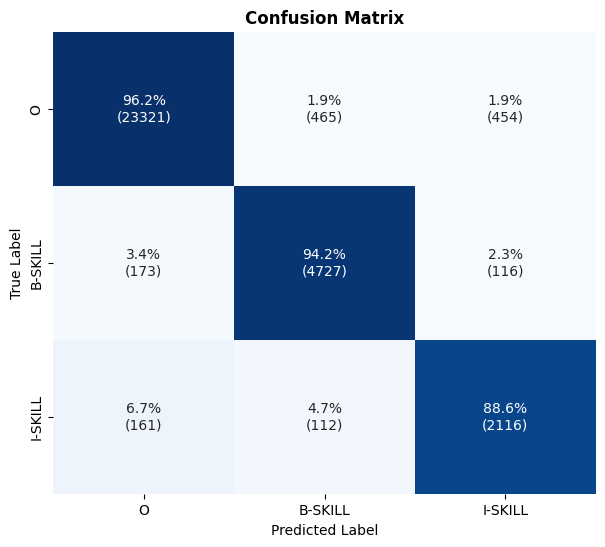

In [56]:
# CELL 15 - Đánh giá trên tập Test
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from seqeval.metrics import classification_report as seq_report

test_results = trainer.predict(tok_ds["test"])
preds = np.argmax(test_results.predictions, axis=2)
labels = test_results.label_ids

flat_true, flat_preds = [], []
for p_seq, l_seq in zip(preds, labels):
    for p, l in zip(p_seq, l_seq):
        if l != -100:
            flat_true.append(LABEL_LIST[l])
            flat_preds.append(LABEL_LIST[p])

seq_true, seq_preds = [], []
for p_seq, l_seq in zip(preds, labels):
    t_l, t_p = [], []
    for p, l in zip(p_seq, l_seq):
        if l != -100:
            t_l.append(LABEL_LIST[l])
            t_p.append(LABEL_LIST[p])
    seq_true.append(t_l)
    seq_preds.append(t_p)

print("\n=== BÁO CÁO ĐÁNH GIÁ (SPAN-LEVEL) ===")
print(seq_report(seq_true, seq_preds))

cm = confusion_matrix(flat_true, flat_preds, labels=LABEL_LIST)
row_sums = cm.sum(axis=1)[:, np.newaxis]
cm_norm = cm.astype('float') / row_sums
annot = np.empty_like(cm).astype(str)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot[i, j] = f"{cm_norm[i, j]*100:.1f}%\n({cm[i, j]})"

plt.figure(figsize=(7, 6))
sns.heatmap(cm_norm, annot=annot, fmt='', cmap='Blues', xticklabels=LABEL_LIST, yticklabels=LABEL_LIST, cbar=False)
plt.title('Confusion Matrix', fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [69]:
# CELL 16 - Hàm trích xuất (Xóa bỏ hoàn toàn @@)
def extract_skills(text):
    inputs = tokenizer(
        text, return_tensors="pt", truncation=True, max_length=MAX_LEN
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
    predictions = torch.argmax(outputs.logits, dim=2)[0].cpu().numpy()

    input_ids = inputs["input_ids"][0].cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids)

    skills = []
    current_ids = []

    for idx, (token, pred) in enumerate(zip(tokens, predictions)):
        if token in [tokenizer.cls_token, tokenizer.sep_token, tokenizer.pad_token]:
            continue

        label = id2label[pred]

        if label == "B-SKILL":
            if current_ids:
                # Xóa @@ và khoảng trắng thừa
                clean_word = tokenizer.decode(current_ids).replace("@@", "").strip()
                if clean_word: skills.append(clean_word)
            current_ids = [input_ids[idx]]
        elif label == "I-SKILL":
            current_ids.append(input_ids[idx])
        else:
            if current_ids:
                clean_word = tokenizer.decode(current_ids).replace("@@", "").strip()
                if clean_word: skills.append(clean_word)
                current_ids = []

    if current_ids:
        clean_word = tokenizer.decode(current_ids).replace("@@", "").strip()
        if clean_word: skills.append(clean_word)

    return skills

In [72]:
# CELL 17 - Từ điển Chuẩn hóa (Đã tối ưu việc tìm kiếm)
TEENCODE_DICT = {
    "vs": "với", "dc": "được", "đc": "được", "ko": "không", "k": "không",
    "ng": "người", "j": "gì", "r": "rồi", "thik": "thích", "bik": "biết",
    "sp": "sản phẩm", "nv": "nhân viên", "cty": "công ty", "trc": "trước"
}

SKILL_SYNONYMS = {
    "js": "JavaScript", "javascript": "JavaScript", "javascripts": "JavaScript",
    "react js": "ReactJS", "reactjs": "ReactJS", "react native": "React Native",
    "c sharp": "C#", "csharp": "C#", "c-sharp": "C#", "c#": "C#",
    "html5": "HTML", "html": "HTML", "css3": "CSS", "css": "CSS",
    "tiếng anh": "Tiếng Anh", "tiếnganh": "Tiếng Anh", "english": "Tiếng Anh", "anh văn": "Tiếng Anh",
    "springboot": "Spring Boot", "sql server": "SQL Server", "mysql": "MySQL",
    "java": "Java"
}

def normalize_vietnamese(text):
    words = text.lower().split()
    return " ".join([TEENCODE_DICT.get(w, w) for w in words])

def canonicalize_skills(skills):
    clean_skills = []
    for s in skills:
        s_norm = normalize_vietnamese(s)
        # Dọn dẹp các dấu câu thừa ở 2 đầu (ví dụ dấu chấm)
        s_norm = s_norm.strip(".,;:- ")

        if s_norm in SKILL_SYNONYMS:
            s_norm = SKILL_SYNONYMS[s_norm]

        if s_norm:
            # Viết hoa chữ cái đầu
            clean_skills.append(s_norm[0].upper() + s_norm[1:])

    return list(dict.fromkeys(clean_skills))

In [71]:
# CELL 18 - Chạy thử nghiệm Inference
sample_cv = """
Tôi là lập trình viên 3 năm kinh nghiệm làm việc vs Java, Spring Boot và ReactJS.
Thành thạo csdl MySQL, SQL Server. Có kiến thức về html5, css3, js.
Biết sử dụng Git và Docker. Kỹ năng giao tiếp tốt, tiếng anh khá.
"""

raw_skills = extract_skills(sample_cv)
print("--- Kỹ năng thô ---")
print(raw_skills)

final_skills = canonicalize_skills(raw_skills)
print("\n--- Kỹ năng chuẩn hóa ---")
print(final_skills)

--- Kỹ năng thô ---
['Java', 'Spring Boot', 'ReactJS.', 'MySQL', 'SQL Server.', 'html5', 'css3', 'js.', 'Git', 'Docker.', 'tiếng anh']

--- Kỹ năng chuẩn hóa ---
['Java', 'Spring boot', 'ReactJS', 'MySQL', 'SQL Server', 'HTML', 'CSS', 'JavaScript', 'Git', 'Docker', 'Tiếng Anh']
